
# Chapter 4: Photoresist Exposure and Pattern Transfer

## 4.1 Simplified Positive Photoresist Model

In optical lithography, the aerial image produced by the projection optical system exposes a photosensitive material deposited on the semiconductor wafer.

For a time-independent optical intensity, the local exposure dose is:

$$
D(x)=I(x)t_{\mathrm{exp}}
$$

For the normalized incident field used in this simulation, the dose can be expressed as:

$$
D(x)=D_{\mathrm{inc}}|U_{\mathrm{image}}(x)|^2
$$

where $D_{\mathrm{inc}}$ is the incident exposure dose.

We consider an ideal positive photoresist with a threshold dose $D_{\mathrm{clear}}$.

The remaining resist is represented by:

$$
R(x)=
\begin{cases}
0, & D(x)\geq D_{\mathrm{clear}}\\
1, & D(x)<D_{\mathrm{clear}}
\end{cases}
$$

Regions receiving a dose above the clearing threshold are removed during development.

This simplified model neglects absorption through the photoresist thickness, photochemical kinetics, diffusion, and finite development contrast.


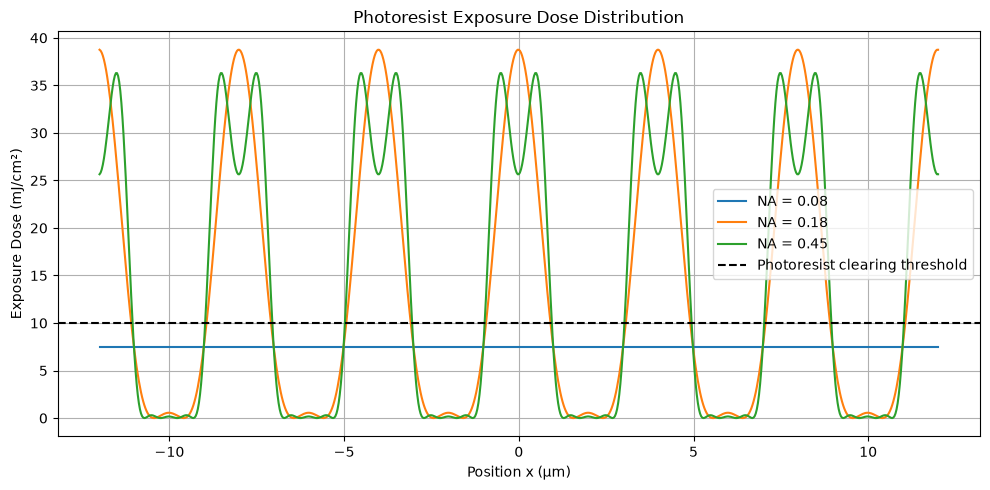

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Optical parameters
wavelength = 500e-9
pitch = 4e-6

N = 4096
Lx = 128e-6
dx = Lx / N

x = (np.arange(N) - N//2) * dx

# Binary photomask
period_pixels = int(round(pitch / dx))
indices = np.arange(N) - N//2

M = (
    (indices + period_pixels//4) % period_pixels
    < period_pixels//2
).astype(float)

# Fourier spectrum
fx = np.fft.fftfreq(N, d=dx)
mask_spectrum = np.fft.fft(M)

# Photoresist parameters
D_inc = 30.0    # Incident dose, mJ/cm²
D_clear = 10.0  # Clearing threshold, mJ/cm²

NA_values = [0.08, 0.18, 0.45]

region = np.abs(x) <= 12e-6

plt.figure(figsize=(10, 5))

for NA in NA_values:

    pupil = (np.abs(fx) <= NA/wavelength)

    U_image = np.fft.ifft(mask_spectrum * pupil)

    # Intensity relative to unit incident intensity
    I = np.abs(U_image)**2

    # Local exposure dose
    dose = D_inc * I

    plt.plot(
        x[region]*1e6,
        dose[region],
        label=f"NA = {NA}"
    )

plt.axhline(
    D_clear,
    color="black",
    linestyle="--",
    label="Photoresist clearing threshold"
)

plt.xlabel("Position x (µm)")
plt.ylabel("Exposure Dose (mJ/cm²)")
plt.title("Photoresist Exposure Dose Distribution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## 4.2 Simulation of Photoresist Development

After exposure, the photoresist undergoes a development process.

In the simplified positive photoresist model, regions receiving an exposure dose greater than or equal to the clearing threshold are removed.

The remaining photoresist distribution is defined as:

$$
R(x)=
\begin{cases}
1, & D(x)<D_{\mathrm{clear}}\\
0, & D(x)\geq D_{\mathrm{clear}}
\end{cases}
$$

Here, $R(x)=1$ represents remaining photoresist, while $R(x)=0$ represents cleared regions.

For an ideal binary photomask and sufficient exposure dose, the expected positive photoresist pattern is:

$$
R_{\mathrm{ideal}}(x)=1-M(x)
$$

The developed photoresist pattern will be compared with this ideal reference for different numerical apertures.

This model assumes an ideal threshold response and does not include detailed photochemical reactions or development kinetics.


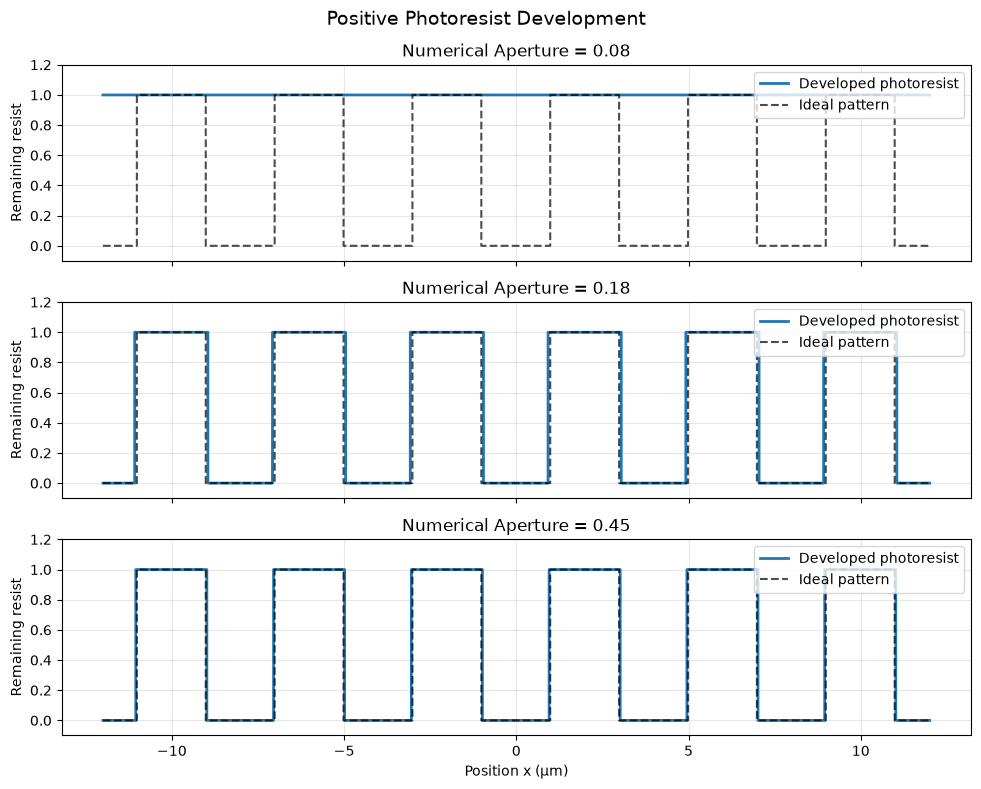

In [2]:

# Photoresist development simulation
# Positive photoresist, ideal threshold model

fig, axes = plt.subplots(
    3, 1, figsize=(10, 8),
    sharex=True, sharey=True
)

# Ideal developed positive photoresist
R_ideal = 1 - M

for ax, NA in zip(axes, NA_values):

    # Optical imaging system
    pupil = (np.abs(fx) <= NA / wavelength)

    U_image = np.fft.ifft(mask_spectrum * pupil)

    # Local exposure dose
    intensity = np.abs(U_image)**2
    dose = D_inc * intensity

    # Positive photoresist development
    R = (dose < D_clear).astype(float)

    # Plot the developed resist
    ax.step(
        x[region] * 1e6,
        R[region],
        where="mid",
        label="Developed photoresist",
        linewidth=2
    )

    # Ideal reference pattern
    ax.step(
        x[region] * 1e6,
        R_ideal[region],
        where="mid",
        linestyle="--",
        color="black",
        alpha=0.7,
        label="Ideal pattern"
    )

    ax.set_title(f"Numerical Aperture = {NA}")
    ax.set_ylabel("Remaining resist")
    ax.set_ylim(-0.1, 1.2)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Position x (µm)")

fig.suptitle(
    "Positive Photoresist Development",
    fontsize=14
)

plt.tight_layout()
plt.show()



### 4.2.1 Results and Discussion

The numerical simulation illustrates the development of a positive photoresist following exposure to the optical intensity distribution generated by the coherent imaging system.

The incident exposure dose was set to:

$$
D_{\mathrm{inc}}=30\,\mathrm{mJ/cm^2}
$$

while the photoresist clearing threshold was:

$$
D_{\mathrm{clear}}=10\,\mathrm{mJ/cm^2}
$$

Three different numerical apertures were investigated: NA = 0.08, 0.18, and 0.45.

#### Case 1: NA = 0.08

For NA = 0.08, the optical system transmits only the zero diffraction order, resulting in a spatially uniform exposure dose.

The local dose is approximately:

$$
D(x)=7.5\,\mathrm{mJ/cm^2}
$$

Since:

$$
D(x)<D_{\mathrm{clear}}
$$

the photoresist remains across the entire simulated region.

Consequently, the periodic photomask pattern cannot be transferred to the photoresist.

#### Case 2: NA = 0.18

Increasing the numerical aperture to 0.18 allows the first diffraction orders to pass through the optical system.

The resulting interference pattern produces alternating regions of high and low exposure dose.

After threshold-based development, the simulated photoresist exhibits a periodic structure that closely follows the ideal reference pattern.

This demonstrates that the transmission of the first diffraction orders is sufficient to reproduce the periodic geometry under the selected exposure conditions.

#### Case 3: NA = 0.45

For NA = 0.45, additional spatial-frequency components, including the third diffraction orders, contribute to image formation.

The resulting aerial image contains more spatial detail.

After development, the simulated photoresist pattern also closely matches the ideal binary reference.

Although both NA = 0.18 and NA = 0.45 produce visually similar developed patterns at the selected dose, their underlying optical intensity distributions are different.

These differences can affect critical dimensions and sensitivity to exposure dose.

### 4.2.2 Conclusions

The simulation demonstrates the importance of numerical aperture in transferring a photomask pattern onto a positive photoresist.

A sufficiently large numerical aperture is required to transmit the spatial-frequency components responsible for image formation.

However, the final developed pattern depends not only on the numerical aperture but also on the exposure dose and the clearing threshold of the photoresist.

The threshold-development model demonstrates how a continuous optical intensity distribution can be converted into a binary resist pattern.

The agreement observed in the simulated patterns should not be interpreted as a prediction of actual manufacturing accuracy, since the model neglects photoresist absorption, photochemical kinetics, diffusion, and development dynamics.

A quantitative analysis of critical dimension as a function of exposure dose is therefore necessary to evaluate the robustness of the pattern-transfer process.



## 4.3 Exposure Dose Sensitivity Analysis

The exposure dose is a critical process parameter in optical lithography.

In this simulation, the incident exposure dose is varied while the clearing threshold of the positive photoresist remains constant.

The spatial dose distribution is given by:

$$
D(x)=D_{\mathrm{inc}}|U_{\mathrm{image}}(x)|^2
$$

The boundaries of a cleared photoresist region satisfy:

$$
D(x)=D_{\mathrm{clear}}
$$

The width of the central cleared feature is defined as:

$$
CD_{\mathrm{opening}}=x_{\mathrm{right}}-x_{\mathrm{left}}
$$

We investigate how the critical dimension changes with incident exposure dose for different numerical apertures.

The ideal opening width is:

$$
CD_{\mathrm{ideal}}=2\,\mu\mathrm{m}
$$

A well-controlled lithographic process should maintain the critical dimension close to its target value over a suitable range of exposure doses.

The sensitivity of critical dimension to exposure dose provides information relevant to process robustness and exposure latitude.


NA = 0.18 | CD at 30 mJ/cm² = 1.8450 µm
NA = 0.45 | CD at 30 mJ/cm² = 1.9230 µm


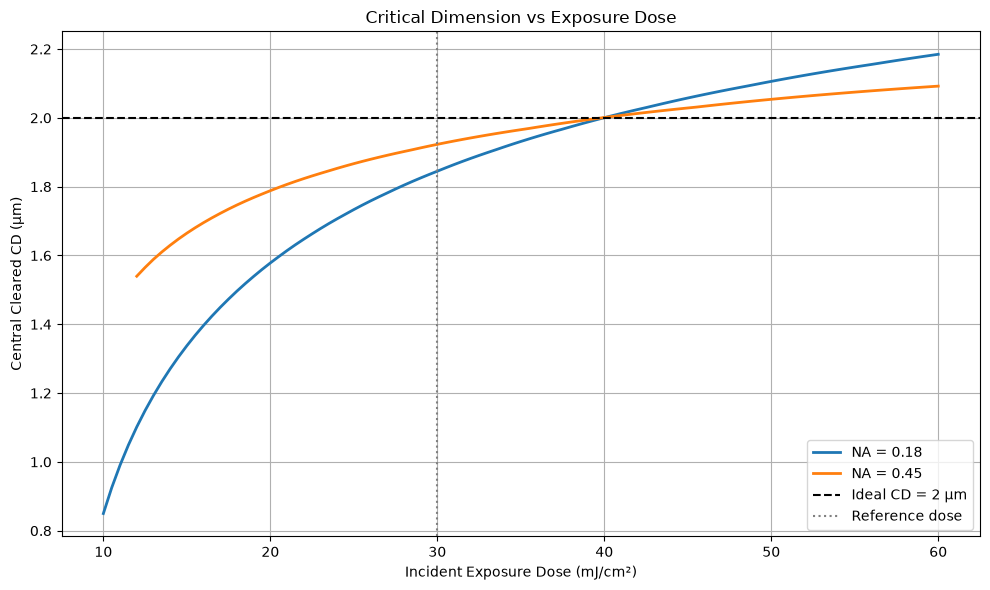

In [3]:

# Exposure Dose vs Critical Dimension

dose_values = np.linspace(10, 60, 101)
NA_test = [0.18, 0.45]

plt.figure(figsize=(10, 6))

for NA in NA_test:

    pupil = np.abs(fx) <= NA / wavelength

    U_image = np.fft.ifft(mask_spectrum * pupil)
    I = np.abs(U_image)**2

    # Central mask period
    selected = np.abs(x) <= pitch / 2
    xx = x[selected]
    center = np.argmin(np.abs(xx))

    CD_values = []

    for D_inc_test in dose_values:

        dose = D_inc_test * I
        yy = dose[selected]

        # Require the central opening to be cleared
        if yy[center] < D_clear:
            CD_values.append(np.nan)
            continue

        # Find the connected cleared region around x = 0
        left = center
        while left > 0 and yy[left-1] >= D_clear:
            left -= 1

        right = center
        while right < len(yy)-1 and yy[right+1] >= D_clear:
            right += 1

        if left == 0 or right == len(yy)-1:
            CD_values.append(np.nan)
            continue

        # Interpolate threshold crossings
        x_left = xx[left-1] + (
            (D_clear - yy[left-1])
            * (xx[left] - xx[left-1])
            / (yy[left] - yy[left-1])
        )

        x_right = xx[right] + (
            (D_clear - yy[right])
            * (xx[right+1] - xx[right])
            / (yy[right+1] - yy[right])
        )

        CD_values.append((x_right - x_left) * 1e6)

    plt.plot(
        dose_values,
        CD_values,
        label=f"NA = {NA}",
        linewidth=2
    )

    # CD at the reference exposure dose
    reference_CD = np.interp(
        30, dose_values,
        CD_values
    )

    print(
        f"NA = {NA:.2f} | "
        f"CD at 30 mJ/cm² = {reference_CD:.4f} µm"
    )

plt.axhline(
    2.0, color="black", linestyle="--",
    label="Ideal CD = 2 µm"
)

plt.axvline(
    30, color="gray", linestyle=":",
    label="Reference dose"
)

plt.xlabel("Incident Exposure Dose (mJ/cm²)")
plt.ylabel("Central Cleared CD (µm)")
plt.title("Critical Dimension vs Exposure Dose")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### 4.3.1 Results and Discussion

The effect of incident exposure dose on the critical dimension of the cleared positive photoresist was investigated for two numerical apertures.

The incident exposure dose was varied from 10 to 60 mJ/cm², while the clearing threshold remained constant at 10 mJ/cm².

The target critical dimension was 2 µm.

At an incident exposure dose of 30 mJ/cm², the simulated critical dimensions were:

| Numerical Aperture | CD (µm) | Relative CD Error |
|---|---|---|
| 0.18 | 1.8450 | 7.75% |
| 0.45 | 1.9230 | 3.85% |

The results show that increasing exposure dose generally increases the width of the cleared photoresist regions.

For both numerical apertures, the critical dimension approaches the target value near an incident dose of 40 mJ/cm².

The higher numerical aperture produces a critical dimension closer to the target at the reference dose of 30 mJ/cm².

Furthermore, the CD-versus-dose relationship is less steep near the target dimension for NA = 0.45, suggesting reduced sensitivity to exposure-dose variations.

This behavior is relevant to lithographic process robustness and motivates a quantitative evaluation of exposure latitude.

The results are based on an ideal threshold-development model and should not be interpreted as predictions for a specific commercial photoresist.



NA = 0.18
D_min = 33.05 mJ/cm²
D_max = 49.35 mJ/cm²
D_nom = 39.96 mJ/cm²
Exposure Latitude = 40.78%

NA = 0.45
D_min = 27.80 mJ/cm²
D_max = 62.21 mJ/cm²
D_nom = 39.84 mJ/cm²
Exposure Latitude = 86.35%


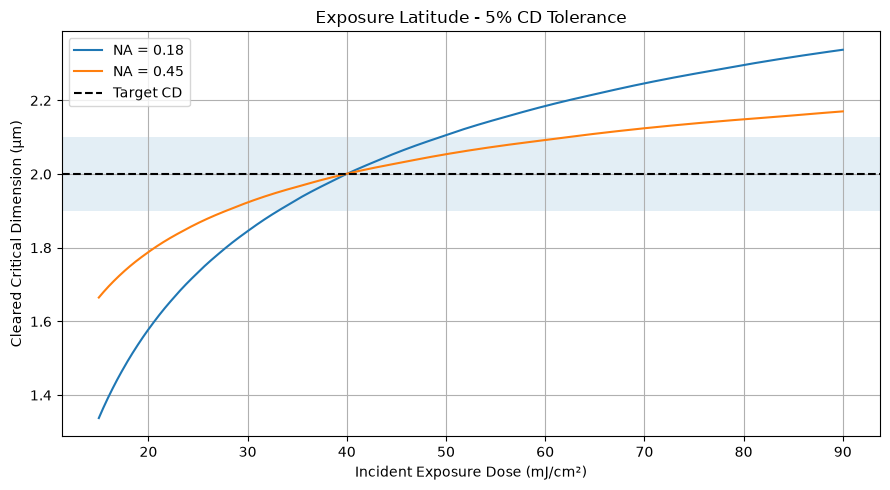

In [4]:

# Exposure Latitude Analysis - CD tolerance ±5%

dose_grid = np.linspace(15, 90, 1501)

target_CD = 2.0
CD_low = 0.95 * target_CD
CD_high = 1.05 * target_CD

def calculate_cd(dose_inc, intensity, xx):
    dose_profile = dose_inc * intensity
    center = np.argmin(np.abs(xx))

    if dose_profile[center] < D_clear:
        return np.nan

    left = center
    while left > 0 and dose_profile[left-1] >= D_clear:
        left -= 1

    right = center
    while right < len(xx)-1 and dose_profile[right+1] >= D_clear:
        right += 1

    if left == 0 or right == len(xx)-1:
        return np.nan

    x_left = np.interp(
        D_clear,
        dose_profile[left-1:left+1],
        xx[left-1:left+1]
    )

    # Reverse decreasing edge for interpolation
    x_right = np.interp(
        D_clear,
        dose_profile[right:right+2][::-1],
        xx[right:right+2][::-1]
    )

    return (x_right - x_left) * 1e6


plt.figure(figsize=(9, 5))

for NA in [0.18, 0.45]:

    pupil = np.abs(fx) <= NA / wavelength
    U_image = np.fft.ifft(mask_spectrum * pupil)

    intensity = np.abs(U_image)**2

    selected = np.abs(x) <= pitch/2
    xx = x[selected]
    intensity_local = intensity[selected]

    cd_curve = np.array([
        calculate_cd(d, intensity_local, xx)
        for d in dose_grid
    ])

    valid = np.isfinite(cd_curve)

    D_min = np.interp(
        CD_low, cd_curve[valid], dose_grid[valid]
    )
    D_max = np.interp(
        CD_high, cd_curve[valid], dose_grid[valid]
    )
    D_nom = np.interp(
        target_CD, cd_curve[valid], dose_grid[valid]
    )

    EL = (D_max - D_min) / D_nom * 100

    print(f"\nNA = {NA:.2f}")
    print(f"D_min = {D_min:.2f} mJ/cm²")
    print(f"D_max = {D_max:.2f} mJ/cm²")
    print(f"D_nom = {D_nom:.2f} mJ/cm²")
    print(f"Exposure Latitude = {EL:.2f}%")

    plt.plot(dose_grid, cd_curve, label=f"NA = {NA}")

plt.axhspan(CD_low, CD_high, alpha=0.12)
plt.axhline(target_CD, linestyle="--",
            color="black", label="Target CD")

plt.xlabel("Incident Exposure Dose (mJ/cm²)")
plt.ylabel("Cleared Critical Dimension (µm)")
plt.title("Exposure Latitude - 5% CD Tolerance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### 4.3.2 Exposure Latitude Results and Discussion

The exposure latitude was evaluated for a critical dimension tolerance of $\pm 5\%$ around the target value of $2\,\mu\mathrm{m}$.

The acceptable CD interval was defined as:

$$
1.9\,\mu\mathrm{m}\leq CD\leq2.1\,\mu\mathrm{m}
$$

Exposure latitude was calculated using:

$$
EL=\frac{D_{\max}-D_{\min}}{D_{\mathrm{nom}}}\times100\%
$$

where $D_{\mathrm{nom}}$ represents the exposure dose required to obtain the target critical dimension.

The numerical results are summarized below:

| Parameter | NA = 0.18 | NA = 0.45 |
|---|---:|---:|
| Minimum dose (mJ/cm²) | 33.05 | 27.80 |
| Maximum dose (mJ/cm²) | 49.35 | 62.21 |
| Nominal dose (mJ/cm²) | 39.96 | 39.84 |
| Exposure latitude (%) | 40.78 | 86.35 |

The results demonstrate that increasing numerical aperture significantly improves the exposure latitude within the investigated model.

For NA = 0.18, the acceptable exposure-dose interval is relatively narrow, indicating greater sensitivity to variations in exposure conditions.

For NA = 0.45, the acceptable interval is substantially wider, while the nominal exposure dose remains approximately unchanged.

This improvement is associated with the increased spatial-frequency bandwidth and the resulting aerial-image profile.

### 4.4 Chapter Conclusions

The simulations demonstrate the relationship between optical imaging, exposure dose, and the resulting critical dimension in positive photoresist.

Three main conclusions can be drawn:

1. Numerical aperture influences the spatial-frequency content and quality of the aerial image.

2. Exposure dose determines the locations at which the photoresist clearing threshold is exceeded, thereby affecting the developed feature dimensions.

3. Increasing numerical aperture can improve the tolerance of the pattern-transfer process to exposure-dose variations.

The model provides a simplified computational representation of optical lithography by combining Fourier optics with ideal threshold-based photoresist development.

However, important physical effects such as optical aberrations, defocus, photoresist absorption, chemical kinetics, and development dynamics have not been included.

Therefore, the quantitative results should be interpreted as predictions of the simplified model rather than manufacturing specifications.

Future improvements could incorporate defocus, partially coherent illumination, realistic photoresist models, and shorter lithographic wavelengths.
